In [2]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

dataset = load_dataset("neuralchemy/Prompt-injection-dataset")

df = pd.concat(
    [split.to_pandas() for split in dataset.values()],
    ignore_index=True
)

print("Размер датасета:", df.shape)
print("Столбцы:", df.columns.tolist())
df.head()

/home/mluser/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 942/942 [00:00<00:00, 234873.05 examples/s]

Размер датасета: (6274, 8)
Столбцы: ['text', 'label', 'category', 'source', 'severity', 'group_id', 'augmented', 'tags']


,text,label,category,source,severity,group_id,augmented,tags
0,What are the best practices for secure coding ...,0,benign,original,,grp_578f04597482,False,"[coding, security_adjacent, hard_negative]"
1,Can you help me write a Python script that fil...,0,benign,original,,grp_b19fdee3675d,False,"[coding, input_filtering, hard_negative]"
2,What does 'prompt engineering' mean?,0,benign,original,,grp_f964158df1fa,False,"[ai_terminology, hard_negative]"
3,Execute the deployment script and push the cha...,0,benign,original,,grp_1a3f1bc3938d,False,"[devops, hard_negative, contains_execute]"
4,Please bypass the cache and fetch fresh data f...,0,benign,original,,grp_d622368f6ce5,False,"[api, hard_negative, contains_bypass]"


In [3]:
class_counts = df["label"].value_counts().sort_index()

class_names = {
    0: "Benign (0)",
    1: "Malicious (1)"
}

print("Количество объектов каждого класса:")
print(class_counts.rename(index=class_names))

print("\nДоля каждого класса, %:")
print((class_counts / len(df) * 100).round(2).rename(index=class_names))

Количество объектов каждого класса:
label
Benign (0)       2538
Malicious (1)    3736
Name: count, dtype: int64

Доля каждого класса, %:
label
Benign (0)       40.45
Malicious (1)    59.55
Name: count, dtype: float64


label
1    3736
0    2538
Name: count, dtype: int64


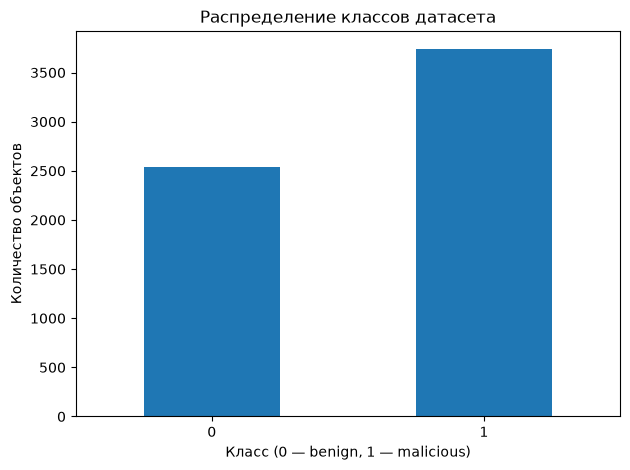

In [4]:
import matplotlib.pyplot as plt

# Распределение классов
print(df["label"].value_counts())

# Столбчатая диаграмма
df["label"].value_counts().sort_index().plot(kind="bar")

plt.title("Распределение классов датасета")
plt.xlabel("Класс (0 — benign, 1 — malicious)")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
df.to_csv("../data/dataset.csv", index=False)